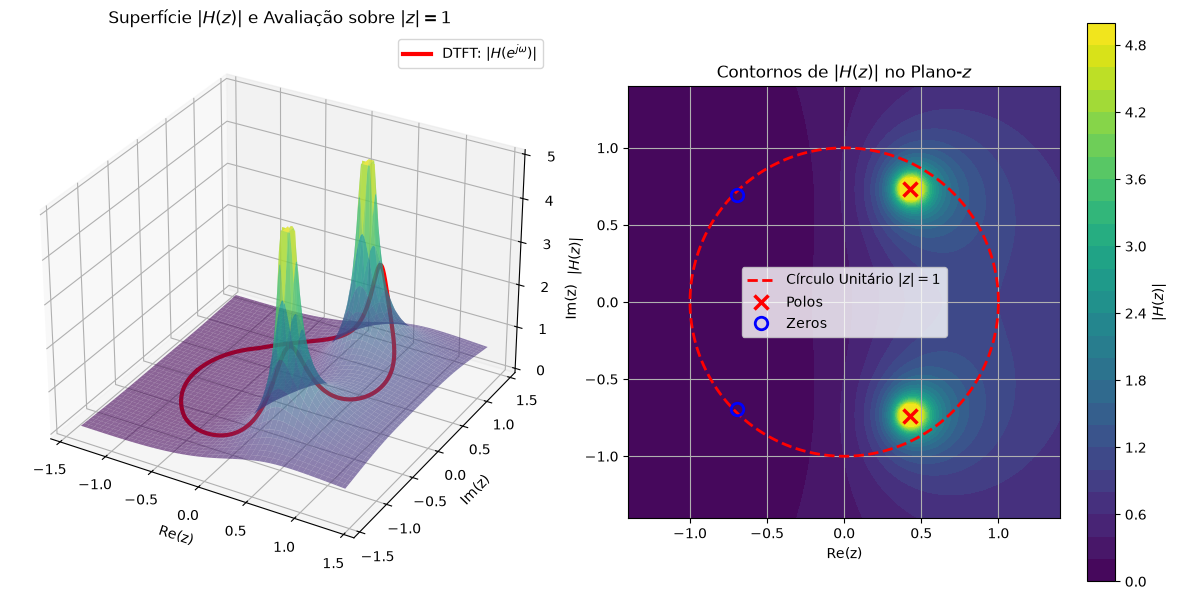

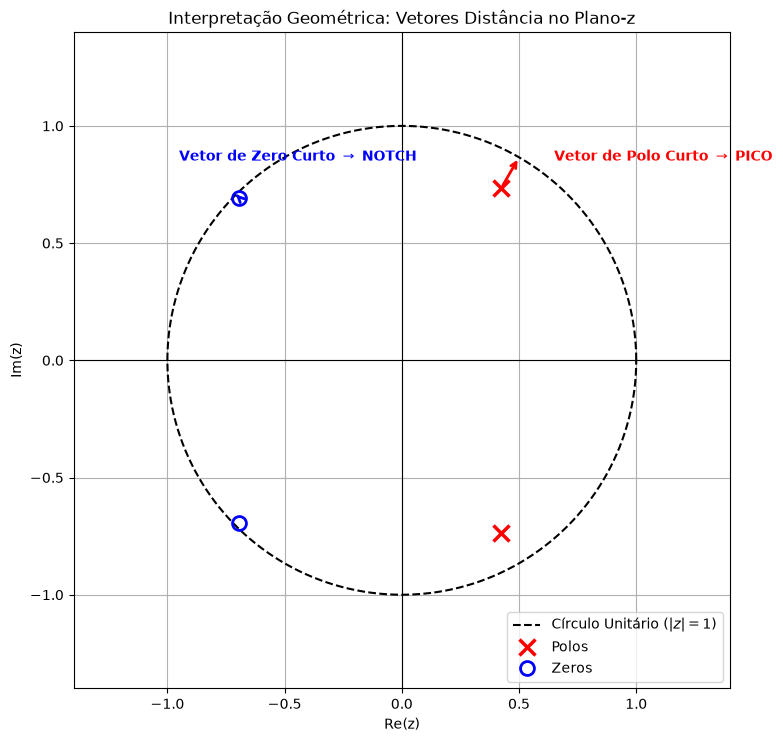

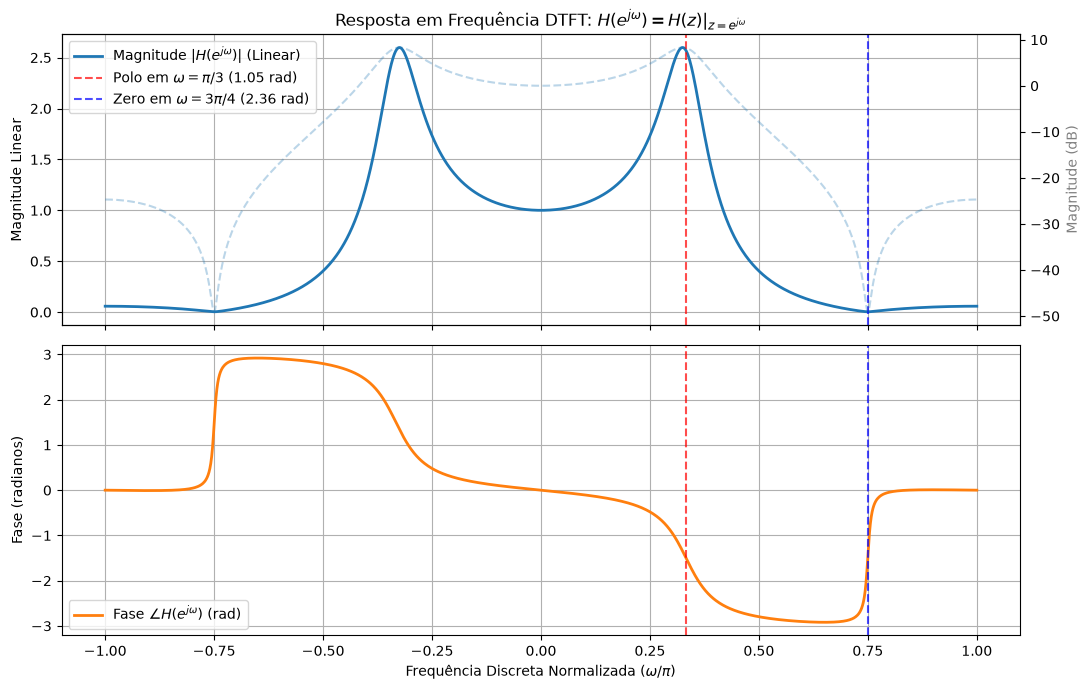

TÓPICO 17 - RELAÇÃO ENTRE TRANSFORMADA-Z E DTFT
Ganho do sistema ajustado K = 0.2607
Polos em z = 0.85e^(±j * pi/3)  -> Módulo = 0.85, Ângulo = 60.0°
Zeros em z = 0.98e^(±j * 3pi/4) -> Módulo = 0.98, Ângulo = 135.0°
--------------------------------------------------------------------------------
Fenômeno Espectral       Freq. Teórica (rad)   Freq. Medida (rad)     Magnitude
--------------------------------------------------------------------------------
Pico de Ressonância      1.0472                1.0220                    2.5987
Notch de Rejeição        2.3562                -2.3554                   0.0035
VERIFICAÇÃO DE PRECISÃO NUMÉRICA (MODELO GEOMÉTRICO MANUAL x SCIPY FREQZ):
  - Erro Máximo na Magnitude: 3.109e-15
  - Erro Máximo Complexo:    3.109e-15


CONCLUSÕES TEÓRICAS DA INVESTIGAÇÃO:
1. Círculo Unitário como Domínio da DTFT:
   A DTFT corresponde exatamente à Transformada-Z avaliada sobre o círculo unitário (z = e^{jw}).
   Ela existe e converge se e somente se o círcul

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal

# ============================================================
# 1. CONFIGURAÇÕES DA SIMULAÇÃO E SISTEMA H(z)
# ============================================================

# Malha de frequências ômega em rad/amostra (de -pi a +pi)
N_W = 1000
w = np.linspace(-np.pi, np.pi, N_W)

# Frequências características escolhidas para a investigação:
# - Polo em w_p = pi/3 (60°): próximo ao círculo unitário (módulo r_p = 0.85) -> Pico de magnitude
# - Zero em w_z = 3*pi/4 (135°): muito próximo ao círculo unitário (módulo r_z = 0.98) -> Rejeição/Notch
r_p, theta_p = 0.85, np.pi / 3
r_z, theta_z = 0.98, 3 * np.pi / 4

# Definição dos pares de polos e zeros complexos conjugados
p1 = complex(r_p * np.cos(theta_p), r_p * np.sin(theta_p))
p2 = complex(r_p * np.cos(theta_p), -r_p * np.sin(theta_p))
polos = [p1, p2]

z1 = complex(r_z * np.cos(theta_z), r_z * np.sin(theta_z))
z2 = complex(r_z * np.cos(theta_z), -r_z * np.sin(theta_z))
zeros = [z1, z2]

# Ganho K escolhido para ganho DC unitário |H(e^{j0})| = 1
# H(1) = K * prod(1 - z_k) / prod(1 - p_k)
prod_p_dc = np.prod(1.0 - np.array(polos))
prod_z_dc = np.prod(1.0 - np.array(zeros))
K_ganho = np.real(prod_p_dc / prod_z_dc)


# ============================================================
# 2. MODELAGEM MATEMÁTICA MANUAL (AVALIAÇÃO DE H(z) SOBRE |z| = 1)
# ============================================================


def avaliar_dtft_geometria(w_eixo, polos, zeros, K):
  """Calcula a DTFT H(e^{jw}) manualmente via interpretacao geometrica de vetores:

  |H(e^{jw})| = K * prod(|e^{jw} - z_k|) / prod(|e^{jw} - p_k|)
  arg(H(e^{jw})) = sum(arg(e^{jw} - z_k)) - sum(arg(e^{jw} - p_k))
  """
  z_circulo = np.exp(1j * w_eixo)
  mag = np.full(len(w_eixo), float(K))
  fase = np.zeros(len(w_eixo))

  # Vetores dos zeros (numerador)
  for zk in zeros:
    vetor_z = z_circulo - zk
    mag *= np.abs(vetor_z)
    fase += np.angle(vetor_z)

  # Vetores dos polos (denominador)
  for pk in polos:
    vetor_p = z_circulo - pk
    mag /= np.abs(vetor_p)
    fase -= np.angle(vetor_p)

  # Ajuste de fase para a faixa de [-pi, pi]
  fase = np.arctan2(np.sin(fase), np.cos(fase))
  H_complexo = mag * np.exp(1j * fase)

  return H_complexo, mag, fase


def avaliar_plano_z_2d(X_grid, Y_grid, polos, zeros, K):
  """Avalia |H(z)| em uma malha 2D do plano complexo z = X + jY."""
  Z_grid = X_grid + 1j * Y_grid
  num = np.ones_like(Z_grid, dtype=complex)
  den = np.ones_like(Z_grid, dtype=complex)

  for zk in zeros:
    num *= Z_grid - zk
  for pk in polos:
    den *= Z_grid - pk

  H_z = K * (num / den)
  return np.abs(H_z)


# Execução da modelagem manual
H_dtft_manual, mag_manual, fase_manual = avaliar_dtft_geometria(
    w, polos, zeros, K_ganho
)


# ============================================================
# 3. VALIDAÇÃO NUMÉRICA COM SCI-PY
# ============================================================

# Obtenção dos coeficientes dos polinômios em potências de z^-1
poly_zeros = np.poly(zeros)  # z^2 + b1 z + b2
poly_polos = np.poly(polos)  # z^2 + a1 z + a2

b_coeff = K_ganho * poly_zeros
a_coeff = poly_polos

# Frequência via scipy.signal.freqz (Parâmetro correto: worN=w)
w_scipy, H_scipy = signal.freqz(b_coeff, a_coeff, worN=w)


# ============================================================
# 4. GRÁFICO 1: SUPERFÍCIE 3D DO PLANO-Z E O CORTE EM |z| = 1 (DTFT)
# ============================================================

fig = plt.figure(figsize=(12, 6))
ax3d = fig.add_subplot(1, 2, 1, projection="3d")

# Malha cartesiana no plano-z
x_range = np.linspace(-1.4, 1.4, 150)
y_range = np.linspace(-1.4, 1.4, 150)
X, Y = np.meshgrid(x_range, y_range)
Z_mag = avaliar_plano_z_2d(X, Y, polos, zeros, K_ganho)
Z_mag_clipped = np.clip(Z_mag, 0, 5.0)  # Limita picos para melhor visualização

# Plota a superfície |H(z)|
surf = ax3d.plot_surface(
    X, Y, Z_mag_clipped, cmap="viridis", alpha=0.6, edgecolor="none"
)

# Traça a linha do círculo unitário sobre a superfície |H(z)| (avaliação da DTFT)
z_unit = np.exp(1j * w)
H_unit_mag = np.clip(np.abs(H_dtft_manual), 0, 5.0)
ax3d.plot(
    np.real(z_unit),
    np.imag(z_unit),
    H_unit_mag,
    color="red",
    linewidth=3,
    label=r"DTFT: $|H(e^{j\omega})|$",
)

ax3d.set_title(r"Superfície $|H(z)|$ e Avaliação sobre $|z| = 1$")
ax3d.set_xlabel("Re(z)")
ax3d.set_ylabel("Im(z)")
ax3d.set_zlabel(r"$|H(z)|$")
ax3d.legend()

# Subplot 2D: Mapa de contornos de |H(z)| com o Círculo Unitário
ax_cont = fig.add_subplot(1, 2, 2)
contour = ax_cont.contourf(X, Y, Z_mag_clipped, levels=30, cmap="viridis")
fig.colorbar(contour, ax=ax_cont, label=r"$|H(z)|$")

# Círculo unitário
theta_c = np.linspace(0, 2 * np.pi, 200)
ax_cont.plot(
    np.cos(theta_c),
    np.sin(theta_c),
    "r--",
    linewidth=2,
    label=r"Círculo Unitário $|z|=1$",
)

# Polos e Zeros
ax_cont.plot(
    np.real(polos),
    np.imag(polos),
    "x",
    color="red",
    markersize=10,
    markeredgewidth=2.5,
    label="Polos",
)
ax_cont.plot(
    np.real(zeros),
    np.imag(zeros),
    "o",
    color="blue",
    markersize=9,
    markerfacecolor="none",
    markeredgewidth=2,
    label="Zeros",
)

ax_cont.set_title(r"Contornos de $|H(z)|$ no Plano-$z$")
ax_cont.set_xlabel("Re(z)")
ax_cont.set_ylabel("Im(z)")
ax_cont.set_aspect("equal", "box")
ax_cont.legend()
ax_cont.grid(True)

plt.tight_layout()
plt.show()


# ============================================================
# 5. GRÁFICO 2: DIAGRAMA DE POLOS/ZEROS E VETORES DISTÂNCIA
# ============================================================

fig, ax_pz = plt.subplots(figsize=(8, 8))

# Círculo unitário
ax_pz.plot(
    np.cos(theta_c),
    np.sin(theta_c),
    "k--",
    linewidth=1.5,
    label=r"Círculo Unitário ($|z| = 1$)",
)
ax_pz.axhline(0, color="k", linewidth=0.8)
ax_pz.axvline(0, color="k", linewidth=0.8)

# Pontos de teste no círculo unitário (nas frequências do polo e zero)
z_p_test = np.exp(1j * theta_p)
z_z_test = np.exp(1j * theta_z)

# Plota Polos e Zeros
ax_pz.plot(
    np.real(polos),
    np.imag(polos),
    "rx",
    markersize=12,
    markeredgewidth=2.5,
    label="Polos",
)
ax_pz.plot(
    np.real(zeros),
    np.imag(zeros),
    "bo",
    markersize=10,
    markerfacecolor="none",
    markeredgewidth=2,
    label="Zeros",
)

# Plota vetores distância para a frequência do polo (w = pi/3)
ax_pz.annotate(
    "",
    xy=(np.real(z_p_test), np.imag(z_p_test)),
    xytext=(np.real(p1), np.imag(p1)),
    arrowprops=dict(arrowstyle="->", color="red", lw=2, ls="-"),
)
ax_pz.text(
    0.65,
    0.85,
    r"Vetor de Polo Curto $\rightarrow$ PICO",
    color="red",
    fontsize=10,
    weight="bold",
)

# Plota vetores distância para a frequência do zero (w = 3pi/4)
ax_pz.annotate(
    "",
    xy=(np.real(z_z_test), np.imag(z_z_test)),
    xytext=(np.real(z1), np.imag(z1)),
    arrowprops=dict(arrowstyle="->", color="blue", lw=2, ls="-"),
)
ax_pz.text(
    -0.95,
    0.85,
    r"Vetor de Zero Curto $\rightarrow$ NOTCH",
    color="blue",
    fontsize=10,
    weight="bold",
)

ax_pz.set_xlim(-1.4, 1.4)
ax_pz.set_ylim(-1.4, 1.4)
ax_pz.set_aspect("equal", "box")
ax_pz.set_title("Interpretação Geométrica: Vetores Distância no Plano-z")
ax_pz.set_xlabel("Re(z)")
ax_pz.set_ylabel("Im(z)")
ax_pz.legend(loc="lower right")
ax_pz.grid(True)

plt.tight_layout()
plt.show()


# ============================================================
# 6. GRÁFICO 3: RESPOSTA EM FREQUÊNCIA DA DTFT (MAGNITUDE E FASE)
# ============================================================

fig, eixos = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

# 1. Magnitude (Linear e dB)
eixos[0].plot(
    w / np.pi,
    mag_manual,
    "C0",
    linewidth=2,
    label=r"Magnitude $|H(e^{j\omega})|$ (Linear)",
)
eixos[0].axvline(
    theta_p / np.pi,
    color="red",
    linestyle="--",
    alpha=0.7,
    label=rf"Polo em $\omega = \pi/3$ ({theta_p:.2f} rad)",
)
eixos[0].axvline(
    theta_z / np.pi,
    color="blue",
    linestyle="--",
    alpha=0.7,
    label=rf"Zero em $\omega = 3\pi/4$ ({theta_z:.2f} rad)",
)
eixos[0].set_ylabel("Magnitude Linear")
eixos[0].set_title(
    r"Resposta em Frequência DTFT: $H(e^{j\omega}) = H(z)\vert_{z=e^{j\omega}}$"
)
eixos[0].legend()
eixos[0].grid(True)

# Eixo secundário em dB
ax_db = eixos[0].twinx()
mag_db = 20 * np.log10(np.maximum(mag_manual, 1e-6))
ax_db.plot(w / np.pi, mag_db, "C0--", alpha=0.3)
ax_db.set_ylabel("Magnitude (dB)", color="gray")

# 2. Resposta de Fase
eixos[1].plot(
    w / np.pi,
    fase_manual,
    "C1",
    linewidth=2,
    label=r"Fase $\angle H(e^{j\omega})$ (rad)",
)
eixos[1].axvline(theta_p / np.pi, color="red", linestyle="--", alpha=0.7)
eixos[1].axvline(theta_z / np.pi, color="blue", linestyle="--", alpha=0.7)
eixos[1].set_xlabel(r"Frequência Discreta Normalizada ($\omega / \pi$)")
eixos[1].set_ylabel("Fase (radianos)")
eixos[1].legend()
eixos[1].grid(True)

plt.tight_layout()
plt.show()


# ============================================================
# 7. RELATÓRIO DE RESULTADOS E ANÁLISE NUMÉRICA
# ============================================================

# Cálculo de pontos de interesse
idx_pico = np.argmax(mag_manual)
w_pico = w[idx_pico]
val_pico = mag_manual[idx_pico]

idx_notch = np.argmin(mag_manual)
w_notch = w[idx_notch]
val_notch = mag_manual[idx_notch]

# Cálculo do erro em relação à biblioteca scipy.signal.freqz
erro_max_mag = np.max(np.abs(mag_manual - np.abs(H_scipy)))
erro_max_complexo = np.max(np.abs(H_dtft_manual - H_scipy))

print("TÓPICO 17 - RELAÇÃO ENTRE TRANSFORMADA-Z E DTFT")
print("=" * 80)
print(f"Ganho do sistema ajustado K = {K_ganho:.4f}")
print(
    f"Polos em z = {r_p:.2f}e^(±j * pi/3)  -> Módulo = {r_p:.2f}, Ângulo ="
    f" {np.degrees(theta_p):.1f}°"
)
print(
    f"Zeros em z = {r_z:.2f}e^(±j * 3pi/4) -> Módulo = {r_z:.2f}, Ângulo ="
    f" {np.degrees(theta_z):.1f}°"
)
print("-" * 80)
print(
    f"{'Fenômeno Espectral':<25}{'Freq. Teórica (rad)':<22}{'Freq. Medida (rad)':<22}{'Magnitude':>10}"
)
print("-" * 80)
print(
    f"{'Pico de Ressonância':<25}{theta_p:<22.4f}{w_pico:<22.4f}{val_pico:>10.4f}"
)
print(
    f"{'Notch de Rejeição':<25}{theta_z:<22.4f}{w_notch:<22.4f}{val_notch:>10.4f}"
)
print("=" * 80)
print(
    "VERIFICAÇÃO DE PRECISÃO NUMÉRICA (MODELO GEOMÉTRICO MANUAL x SCIPY"
    " FREQZ):"
)
print(f"  - Erro Máximo na Magnitude: {erro_max_mag:.3e}")
print(f"  - Erro Máximo Complexo:    {erro_max_complexo:.3e}")

print("\n\nCONCLUSÕES TEÓRICAS DA INVESTIGAÇÃO:")
print("=" * 80)
print(
    "1. Círculo Unitário como Domínio da DTFT:\n"
    "   A DTFT corresponde exatamente à Transformada-Z avaliada sobre o"
    " círculo unitário (z = e^{jw}).\n"
    "   Ela existe e converge se e somente se o círculo unitário estiver contido"
    " na Região de Convergência (ROC).\n"
)
print(
    "2. Efeito da Proximidade dos Polos (Aumento da Magnitude):\n"
    "   Conforme o ponto z = e^{jw} se aproxima de um polo (como em w = pi/3),"
    " o vetor de distância\n"
    "   |e^{jw} - p_k| diminui no denominador de H(z), provocando um pico de"
    " ressonância no espectro.\n"
)
print(
    "3. Efeito da Proximidade dos Zeros (Redução da Magnitude):\n"
    "   Conforme o ponto z = e^{jw} se aproxima de um zero (como em w = 3pi/4),"
    " o vetor de distância\n"
    "   |e^{jw} - z_k| diminui no numerador de H(z), produzindo uma atenuação"
    " acentuada (notch).\n"
)

print("Simulação do Tópico 17 concluída com sucesso!")
